# 25 - Análise de sobreposição 2017–2021

| | |
|---|---|
| **Tarefa do plano** | S2-08 - Landsat×S2, ERA5×SMAP, CHIRPS×IMERG, JRC×S1 (R² e viés) |
| **O que faz** | Prova de coerência: mede se fontes independentes dizem o mesmo quando existem ao mesmo tempo |
| **Usa** | Todos os dados da Semana 1 e as séries dos notebooks 22–24 |
| **Produz** | `reports/semana_2/25_sobreposicao_resumo.csv` e figuras |

**Porque é importante.** O projeto junta satélites que começaram em anos
diferentes. Entre 2017 e 2021 todos existem ao mesmo tempo. Se nesse período
concordam entre si, pode-se confiar em usá-los em conjunto nos outros anos. Estes
números são o pilar 1 da confiabilidade e entram no relatório OAD.

| Medida | Significado | Ideal |
|---|---|---|
| R² | quanto as duas fontes sobem e descem juntas | 1 |
| viés (bias) | diferença média sistemática (segunda − primeira) | 0 |
| RMSE | erro típico entre as duas | 0 |
| AUC | capacidade de um valor contínuo separar duas classes | 1 (0,5 = acaso) |

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "config.yaml").exists())
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ete import config, drivers, features, rasters, series, training
from ete import grid as G

cfg = config.load_config()
P = cfg["processing"]
REPORTS = config.path(cfg, "reports", "semana_2")       # figuras e tabelas para o relatório
pd.set_option("display.float_format", "{:,.3f}".format)

from sklearn.metrics import roc_auc_score
from ete import overlap

start, end = P["overlap"]["start"][:7], P["overlap"]["end"][:7]
months = [m for m in pd.period_range(start, end, freq="M").strftime("%Y-%m")]
summary = []

## 1. Landsat × Sentinel-2 (índices espectrais)

Mesmos píxeis, mesmo mês. O Sentinel-2 (10 m) é primeiro reduzido ao píxel de 30 m
do Landsat. Só entram píxeis vistos sem nuvens pelos dois.

174,882 pares de píxeis em 59 meses


,par,variável,n,r2,bias,rmse,slope
0,Landsat × Sentinel-2,NDWI,174882,0.868,0.035,0.164,0.863
1,Landsat × Sentinel-2,MNDWI,174882,0.926,-0.006,0.128,0.940
2,Landsat × Sentinel-2,NDVI,174882,0.844,-0.036,0.174,0.850
3,Landsat × Sentinel-2,NDMI,174882,0.298,-0.038,0.212,0.447
4,Landsat × Sentinel-2,NDMI (só em terra),133648,0.877,-0.064,0.087,0.917


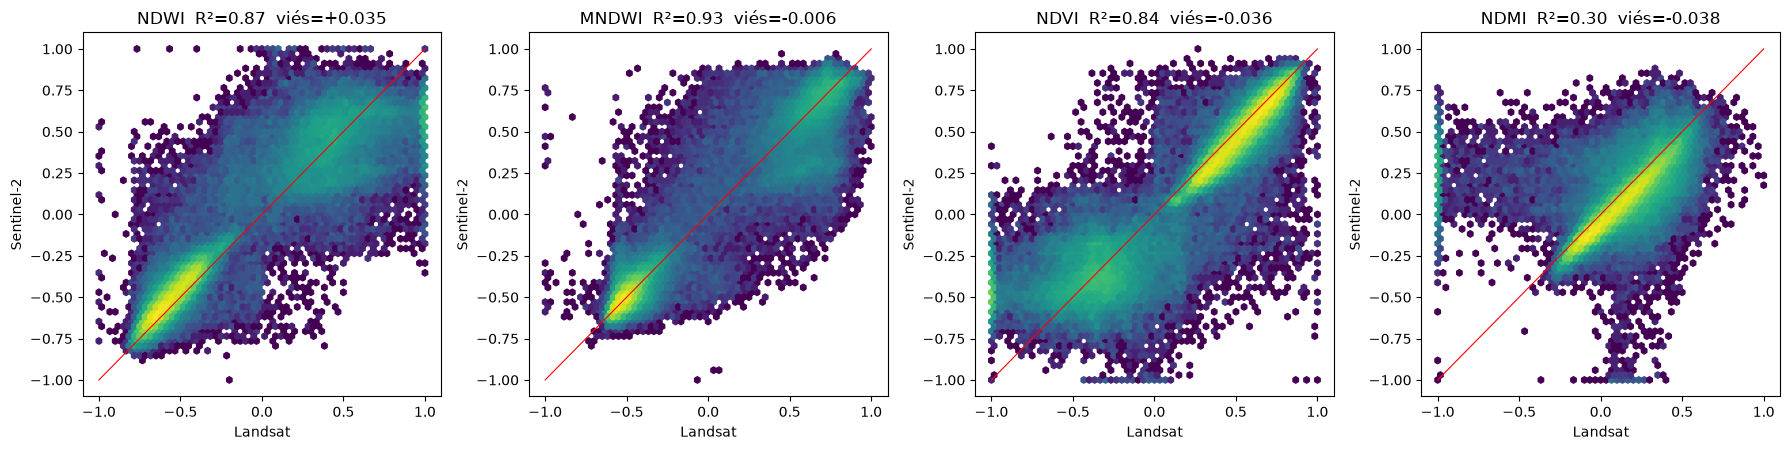

In [2]:
ls2 = overlap.landsat_vs_sentinel2(cfg, months)
print(f"{len(ls2):,} pares de píxeis em {ls2['month'].nunique()} meses")
for name in ["ndwi", "mndwi", "ndvi", "ndmi"]:
    summary.append({"par": "Landsat × Sentinel-2", "variável": name.upper(), **features.agreement(ls2[f"{name}_landsat"], ls2[f"{name}_s2"])})
land = ls2[~ls2["often_water"]]
summary.append({"par": "Landsat × Sentinel-2", "variável": "NDMI (só em terra)", **features.agreement(land["ndmi_landsat"], land["ndmi_s2"])})

fig, axes = plt.subplots(1, 4, figsize=(18, 4.6))
for ax, name in zip(axes, ["ndwi", "mndwi", "ndvi", "ndmi"]):
    ax.hexbin(ls2[f"{name}_landsat"], ls2[f"{name}_s2"], gridsize=60, bins="log", cmap="viridis", extent=(-1, 1, -1, 1))
    ax.plot([-1, 1], [-1, 1], color="red", linewidth=0.8)
    stats = summary[["ndwi", "mndwi", "ndvi", "ndmi"].index(name)]
    ax.set_title(f"{name.upper()}  R²={stats['r2']:.2f}  viés={stats['bias']:+.3f}"); ax.set_xlabel("Landsat"); ax.set_ylabel("Sentinel-2")
plt.tight_layout(); plt.savefig(REPORTS / "25_landsat_vs_sentinel2.png", dpi=110)
pd.DataFrame(summary)

**Nota sobre o NDMI.** O NDMI divide pela soma de duas bandas de infravermelho.
Sobre a água as duas são quase zero, e dividir por quase zero dá valores
instáveis, diferentes de satélite para satélite. Por isso o NDMI é também
medido só em terra, onde é usado.

## 2. ERA5-Land × SMAP (humidade do solo, diária, bacia)

In [3]:
hyd = drivers.read_table(cfg, "hydromet_daily").loc[P["overlap"]["start"]:P["overlap"]["end"]]
cal = drivers.read_table(cfg, "soil_moisture_calibrated_daily").loc[P["overlap"]["start"]:P["overlap"]["end"]]
summary.append({"par": "SMAP × ERA5-Land original", "variável": "humidade superfície (bacia)", **features.agreement(hyd["smap_surface_basin"], hyd["sm_era5_l1_basin"])})
summary.append({"par": "SMAP × ERA5-Land calibrado", "variável": "humidade superfície (bacia)", **features.agreement(hyd["smap_surface_basin"], cal["sm_cal_basin"])})
pd.DataFrame(summary[-2:])

,par,variável,n,r2,bias,rmse,slope
0,SMAP × ERA5-Land original,humidade superfície (bacia),1826,0.798,0.112,0.117,1.427
1,SMAP × ERA5-Land calibrado,humidade superfície (bacia),1826,0.803,-0.001,0.019,0.910


Nota: o período de sobreposição coincide com o período de calibração do notebook
24, por isso a linha "calibrado" é otimista. A prova independente da correção é o
teste em 2022+ desse notebook.

## 3. CHIRPS × IMERG (chuva na bacia)

Compara-se por mês e por períodos de 5 dias. Dia a dia não faz sentido: os dois
produtos não contam o "dia" à mesma hora.

,par,variável,n,r2,bias,rmse,slope
0,CHIRPS × IMERG,"chuva mensal (bacia, mm)",60,0.907,-12.722,24.088,0.809
1,CHIRPS × IMERG,"chuva de 5 dias (bacia, mm)",366,0.741,-2.086,8.479,0.726


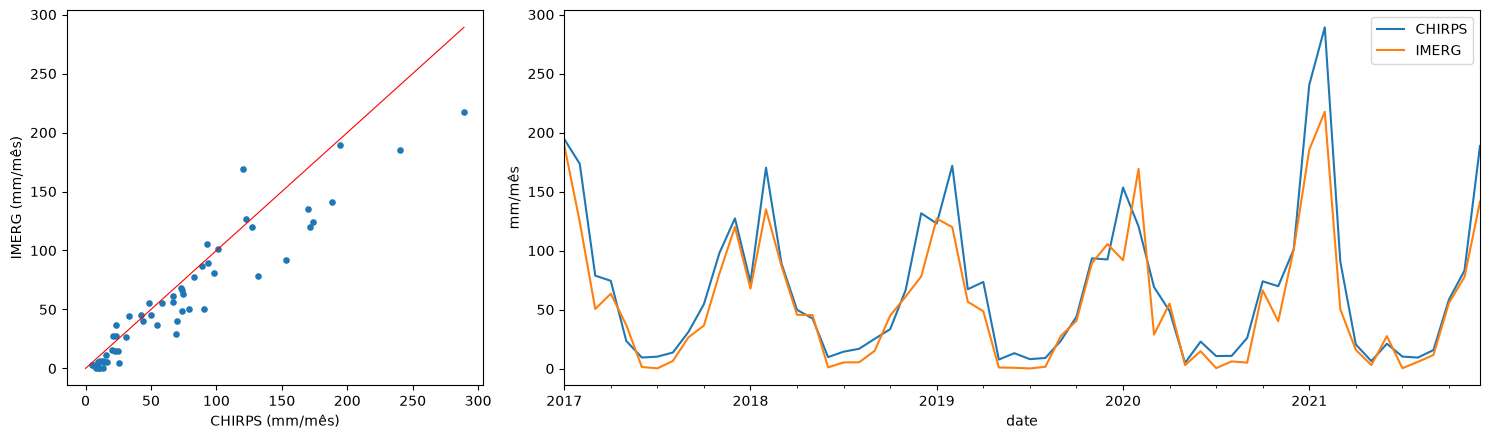

In [4]:
rain = drivers.read_table(cfg, "rain_daily").loc[P["overlap"]["start"]:P["overlap"]["end"]]
five = rain[["rain_basin", "imerg_basin"]].resample("5D").sum()
month_sum = rain[["rain_basin", "imerg_basin"]].resample("MS").sum()
summary.append({"par": "CHIRPS × IMERG", "variável": "chuva mensal (bacia, mm)", **features.agreement(month_sum["rain_basin"], month_sum["imerg_basin"])})
summary.append({"par": "CHIRPS × IMERG", "variável": "chuva de 5 dias (bacia, mm)", **features.agreement(five["rain_basin"], five["imerg_basin"])})

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), width_ratios=[1, 2.2])
axes[0].scatter(month_sum["rain_basin"], month_sum["imerg_basin"], s=14); lim = month_sum.max().max()
axes[0].plot([0, lim], [0, lim], color="red", linewidth=0.8); axes[0].set_xlabel("CHIRPS (mm/mês)"); axes[0].set_ylabel("IMERG (mm/mês)")
month_sum.plot(ax=axes[1]); axes[1].set_ylabel("mm/mês"); axes[1].legend(["CHIRPS", "IMERG"])
plt.tight_layout(); plt.savefig(REPORTS / "25_chirps_vs_imerg.png", dpi=110)
pd.DataFrame(summary[-2:])

## 4. JRC × Sentinel-1 (água)

O JRC diz "água / não água" (a partir do Landsat); o Sentinel-1 dá um valor de
radar. Aqui não se calcula R²: mede-se se o radar separa as duas classes do JRC
(AUC) e quanto mais escura é a água. São dois sensores que veem a água de formas
completamente diferentes, por isso a concordância é uma prova forte.

202,112 píxeis em 51 meses com JRC e Sentinel-1


,par,variável,n,r2,bias,rmse,slope,auc
0,JRC × Sentinel-1,VV separa água de não-água (AUC),202112,NaN,-6.780,NaN,NaN,0.954
1,JRC × Sentinel-1,só fora da água permanente (AUC),113130,NaN,-4.670,NaN,NaN,0.819


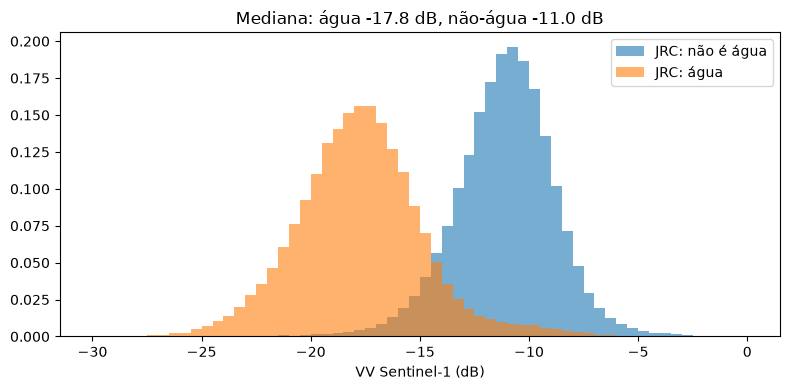

In [5]:
js = overlap.jrc_vs_sentinel1(cfg, months)
print(f"{len(js):,} píxeis em {js['month'].nunique()} meses com JRC e Sentinel-1")
vv_water, vv_land = js.loc[js["jrc_water"], "vv"].median(), js.loc[~js["jrc_water"], "vv"].median()
summary.append({"par": "JRC × Sentinel-1", "variável": "VV separa água de não-água (AUC)", "n": len(js), "r2": np.nan,
                "bias": vv_water - vv_land, "rmse": np.nan, "slope": np.nan, "auc": roc_auc_score(js["jrc_water"], -js["vv"])})
flood = js[~js["permanent"]]
summary.append({"par": "JRC × Sentinel-1", "variável": "só fora da água permanente (AUC)", "n": len(flood), "r2": np.nan,
                "bias": flood.loc[flood["jrc_water"], "vv"].median() - flood.loc[~flood["jrc_water"], "vv"].median(),
                "rmse": np.nan, "slope": np.nan, "auc": roc_auc_score(flood["jrc_water"], -flood["vv"])})

fig, ax = plt.subplots(figsize=(8, 4))
bins = np.linspace(-30, 0, 61)
ax.hist(js.loc[~js["jrc_water"], "vv"], bins, alpha=0.6, label="JRC: não é água", density=True)
ax.hist(js.loc[js["jrc_water"], "vv"], bins, alpha=0.6, label="JRC: água", density=True)
ax.set_xlabel("VV Sentinel-1 (dB)"); ax.legend(); ax.set_title(f"Mediana: água {vv_water:.1f} dB, não-água {vv_land:.1f} dB")
plt.tight_layout(); plt.savefig(REPORTS / "25_jrc_vs_sentinel1.png", dpi=110)
pd.DataFrame(summary[-2:])

Na linha JRC × Sentinel-1, a coluna `bias` é a diferença de VV entre água e
não-água (em dB): quanto mais negativa, mais clara a separação.

## 5. Resumo para o relatório

In [6]:
resumo = pd.DataFrame(summary).set_index(["par", "variável"])
resumo.round(3).to_csv(REPORTS / "25_sobreposicao_resumo.csv")
resumo

n    r2  \
par                        variável                                         
Landsat × Sentinel-2       NDWI                              174882 0.868   
                           MNDWI                             174882 0.926   
                           NDVI                              174882 0.844   
                           NDMI                              174882 0.298   
                           NDMI (só em terra)                133648 0.877   
SMAP × ERA5-Land original  humidade superfície (bacia)         1826 0.798   
SMAP × ERA5-Land calibrado humidade superfície (bacia)         1826 0.803   
CHIRPS × IMERG             chuva mensal (bacia, mm)              60 0.907   
                           chuva de 5 dias (bacia, mm)          366 0.741   
JRC × Sentinel-1           VV separa água de não-água (AUC)  202112   NaN   
                           só fora da água permanente (AUC)  113130   NaN   

                                                               bias   rmse  \
par                        variável                                          
Landsat × Sentinel-2       NDWI                               0.035  0.164   
                           MNDWI                             -0.006  0.128   
                           NDVI                              -0.036  0.174   
                           NDMI                              -0.038  0.212   
                           NDMI (só em terra)                -0.064  0.087   
SMAP × ERA5-Land original  humidade superfície (bacia)        0.112  0.117   
SMAP × ERA5-Land calibrado humidade superfície (bacia)       -0.001  0.019   
CHIRPS × IMERG             chuva mensal (bacia, mm)         -12.722 24.088   
                           chuva de 5 dias (bacia, mm)       -2.086  8.479   
JRC × Sentinel-1           VV separa água de não-água (AUC)  -6.780    NaN   
                           só fora da água permanente (AUC)  -4.670    NaN   

                                                             slope   auc  
par                        variável                                       
Landsat × Sentinel-2       NDWI                              0.863   NaN  
                           MNDWI                             0.940   NaN  
                           NDVI                              0.850   NaN  
                           NDMI                              0.447   NaN  
                           NDMI (só em terra)                0.917   NaN  
SMAP × ERA5-Land original  humidade superfície (bacia)       1.427   NaN  
SMAP × ERA5-Land calibrado humidade superfície (bacia)       0.910   NaN  
CHIRPS × IMERG             chuva mensal (bacia, mm)          0.809   NaN  
                           chuva de 5 dias (bacia, mm)       0.726   NaN  
JRC × Sentinel-1           VV separa água de não-água (AUC)    NaN 0.954  
                           só fora da água permanente (AUC)    NaN 0.819

**Como interpretar**

- R² alto com viés pequeno: as duas fontes podem ser usadas em conjunto.
- R² alto com viés grande: concordam na forma mas não na escala; é o caso que o
  quantile mapping resolve.
- R² baixo: as fontes medem coisas diferentes ou uma delas tem ruído; essa
  variável deve ser usada com cuidado e o motivo explicado no relatório.